# 05 · From a simulation snapshot to τ (TNG50-4)

`skewerjax.simulations` turns a hydrodynamical snapshot into what the core needs. Layers:

| layer | module | does | arrays |
|---|---|---|---|
| 1 | `readers` | HDF5 I/O and units (`ArepoHDF5Reader`) | NumPy |
| 2 | `gas_cells` | `GasCells`: positions, volumes, physical fields | pytree |
| 3 | `gas_physics` | n_H, T, x_HI, metal ion fractions (CLOUDY) per cell | JAX |
| 4 | `selection` | the cells that can reach the skewers (k-d tree, streamed) | NumPy |
| 5 | `deposition` | which cell fills which piece of every dual segment (Voronoi, or fake_spectra's top hats) | NumPy + JAX |
| 6 | `absorbers` | pieces → `core.LoSSamples` → `core.optical_depth_from_samples` | JAX |

`SimulationSkewers` runs them for any `ExtractionOptions` / `IntegrationOptions` (defaults: SkewerJAX's). Data:
TNG50-4 snapshot 25 (z = 3.0, 35 cMpc/h, 19.3 M cells), read-only. Runtime: ~2 min.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")
import logging; logging.getLogger("jax._src.xla_bridge").setLevel(logging.CRITICAL)
import numpy as np, jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)          # SkewerJAX follows this flag; it never sets it itself
import matplotlib.pyplot as plt
from skewerjax.utils.plotting import (use_style, ENTITY_COLORS as EC, MODE_STYLES as MS, TOL_BRIGHT as TOL, LABELS, FIGSIZES,
                                      add_panel_letters, plot_pipeline, plot_spectra, zoom_inset)
use_style()
%matplotlib inline
from skewerjax.core import LineBundle, SkewerBundle, Cosmology, phys
from skewerjax.simulations import ArepoHDF5Reader, SimulationSkewers, ExtractionOptions, IntegrationOptions, HI, Ion, gas_physics as gp
reader = ArepoHDF5Reader("/home/STORAGE/TNG50-4", 25)
H = reader.header
print(f"z = {H.redshift:.4f}, a = {H.a:.6f}, box = {H.box_cMpc:.4f} cMpc, {H.n_gas:,} gas cells in {H.n_files} files, "
      f"a H(z) L = {H.vmax_kms:.1f} km/s")

z = 3.0081, a = 0.249493, box = 51.6681 cMpc, 19,250,411 gas cells in 11 files, a H(z) L = 3961.5 km/s


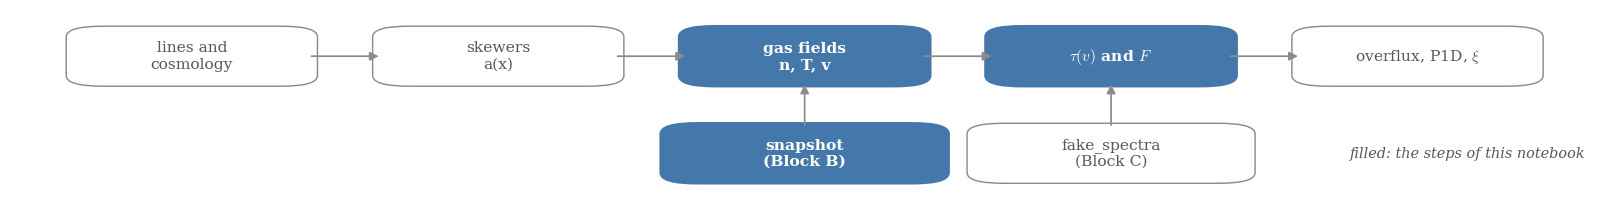

In [2]:
plot_pipeline(('simulation', 'fields', 'tau'), note="filled: the steps of this notebook"); plt.show()

## 1 · Per-cell physics (layer 3)

TNG stores x_HI from its own ionisation equilibrium; SkewerJAX keeps it, recomputing only star-forming cells (cold phase, Rahmati+13).

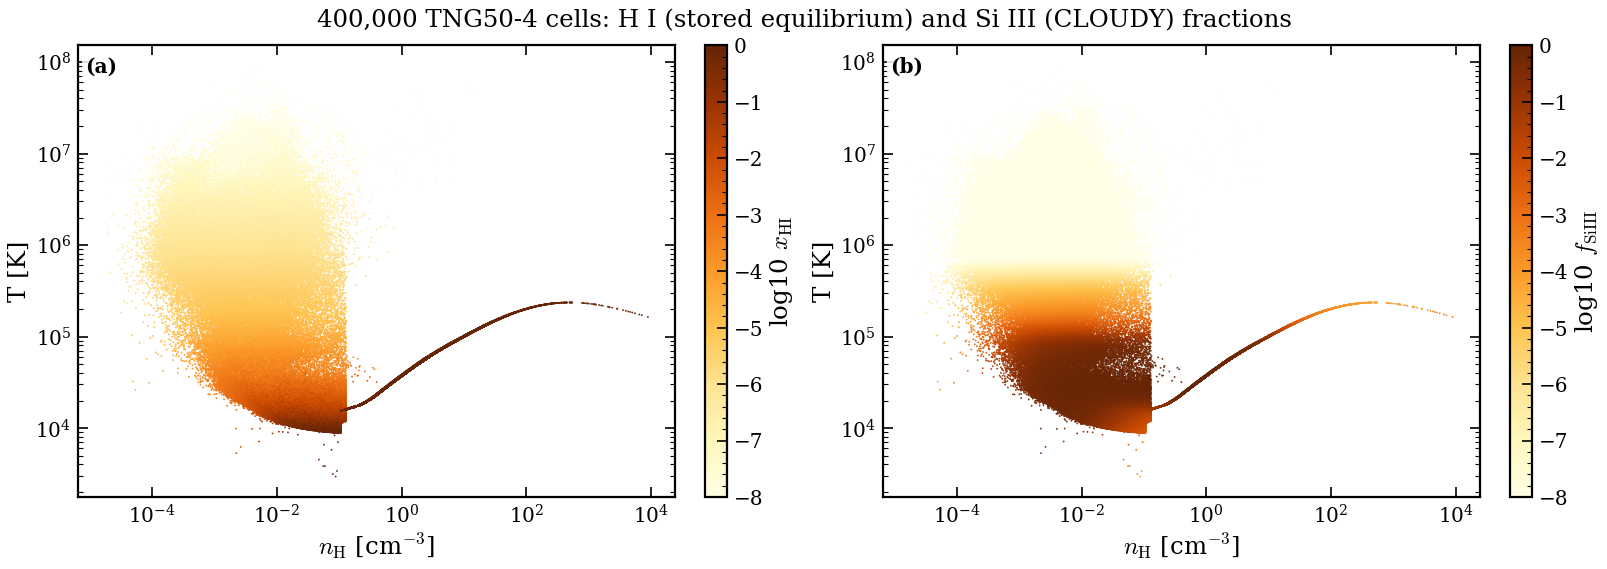

In [3]:
cells = reader.to_gas_cells(reader.read_rows(0, ["Coordinates", "Masses", "Density", "InternalEnergy", "ElectronAbundance",
                                                    "NeutralHydrogenAbundance", "GFM_Metals", "StarFormationRate", "Velocities"], stop=400_000))
P_HI, P_Si = gp.ion_properties(cells, HI), gp.ion_properties(cells, Ion("Si", 3))
from skewerjax.utils.plotting import tol_cmap
fig, axs = plt.subplots(1, 2, figsize=(20, 7), layout="constrained")
for ax, P, name in ((axs[0], P_HI, r"$x_{\rm HI}$"), (axs[1], P_Si, r"$f_{\rm SiIII}$")):
    sc = ax.scatter(np.asarray(P["n_H"]), np.asarray(P["T"]), c=np.log10(np.maximum(np.asarray(P["ion_fraction"]), 1e-12)), s=0.4,
                    cmap=tol_cmap("YlOrBr"), vmin=-8, vmax=0, rasterized=True)
    fig.colorbar(sc, ax=ax, label=f"log10 {name}"); ax.set(xscale="log", yscale="log", xlabel=r"$n_{\rm H}$ [cm$^{-3}$]", ylabel="T [K]")
add_panel_letters(axs); fig.suptitle("400,000 TNG50-4 cells: H I (stored equilibrium) and Si III (CLOUDY) fractions", fontsize=22); plt.show()

## 2 · Skewers and deposition (layers 4–5)

Any `SkewerBundle` can be used (`SimulationSkewers.from_bundle`, with its own a(x)); here three straight skewers along
x, sampled every 0.25 km/s of Hubble flow. Each point stands for its dual segment, and the deposition finds the exact
pieces of the Voronoi cells inside it, so the column is conserved for any spacing.

14,623 cells selected in 4.7 s


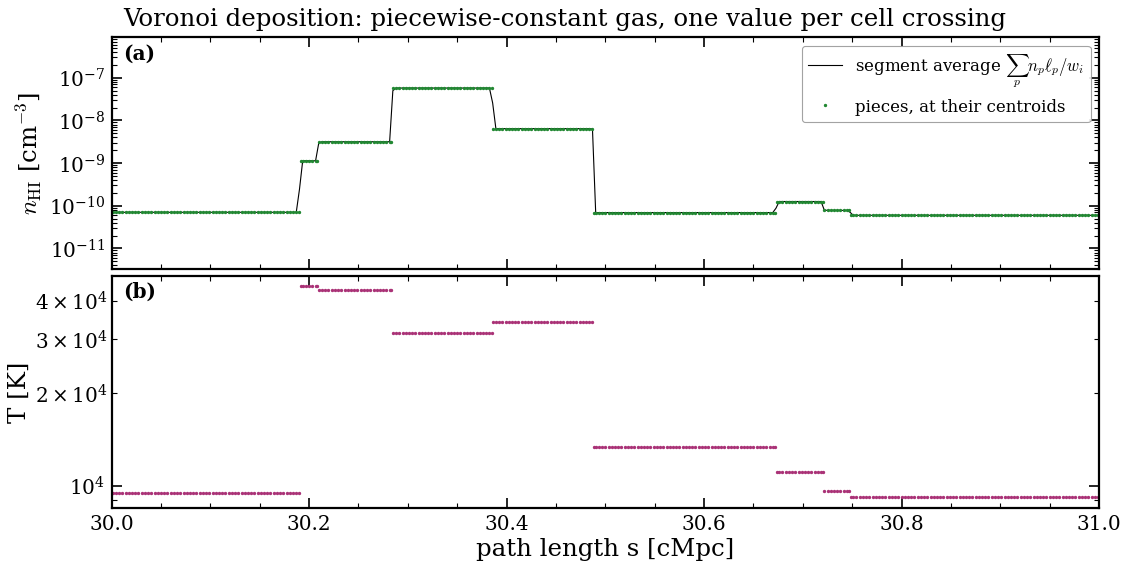

In [4]:
cosmo = Cosmology(H0=100 * H.h * 1e6 * phys.Gyr_to_s / phys.Gpc_to_m, Omega_r_0=0.0, Omega_m_0=H.omega_m, Omega_k_0=0.0, Omega_lambda_0=H.omega_l)
L = H.box_cMpc
x = np.linspace(0.0, L, int(round(H.vmax_kms / 0.25)) + 1)
points = np.stack([np.stack([x, np.full_like(x, y), np.full_like(x, z)], -1) for y, z in [(10.0, 30.0), (25.0, 5.0), (40.0, 45.0)]])
bundle = SkewerBundle(spatial_points=jnp.asarray(points), a0=H.a, ICs_defined_at_index=0, ICs_at_emission_or_absorption="absorption", cosmologies=cosmo)
sk = SimulationSkewers.from_bundle(reader, bundle)
print(f"{len(sk.cells):,} cells selected in {sk.selection_s:.1f} s")
seg = sk.segments("voronoi"); A = sk.absorbers(HI)
win = (A.s[0] > 30) & (A.s[0] < 31) & (A.n[0] > 0)
pv = sk.point_values(HI)
fig, axs = plt.subplots(2, 1, figsize=(14, 7), sharex=True, layout="constrained")
axs[0].semilogy(sk.s[0], pv["n"][0], color="k", lw=1, label=r"segment average $\sum_p n_p\ell_p / w_i$")
axs[0].semilogy(A.s[0][win], A.n[0][win], ".", color=EC["density"], ms=4, label="pieces, at their centroids")
axs[1].semilogy(A.s[0][win], A.T[0][win], ".", color=EC["temperature"], ms=4)
axs[0].set(xlim=(30, 31), ylabel=r"$n_{\rm HI}$ [cm$^{-3}$]"); axs[1].set(xlabel="path length s [cMpc]", ylabel="T [K]"); axs[0].legend()
add_panel_letters(axs); fig.suptitle("Voronoi deposition: piecewise-constant gas, one value per cell crossing", fontsize=22); plt.show()

## 3 · τ and F (layer 6)

`optical_depth(lines)` integrates every line in its own frame over one period of the box (1 km/s pixels by default); `fields(species)` gives the same gas as a `core.Fields` at the points.

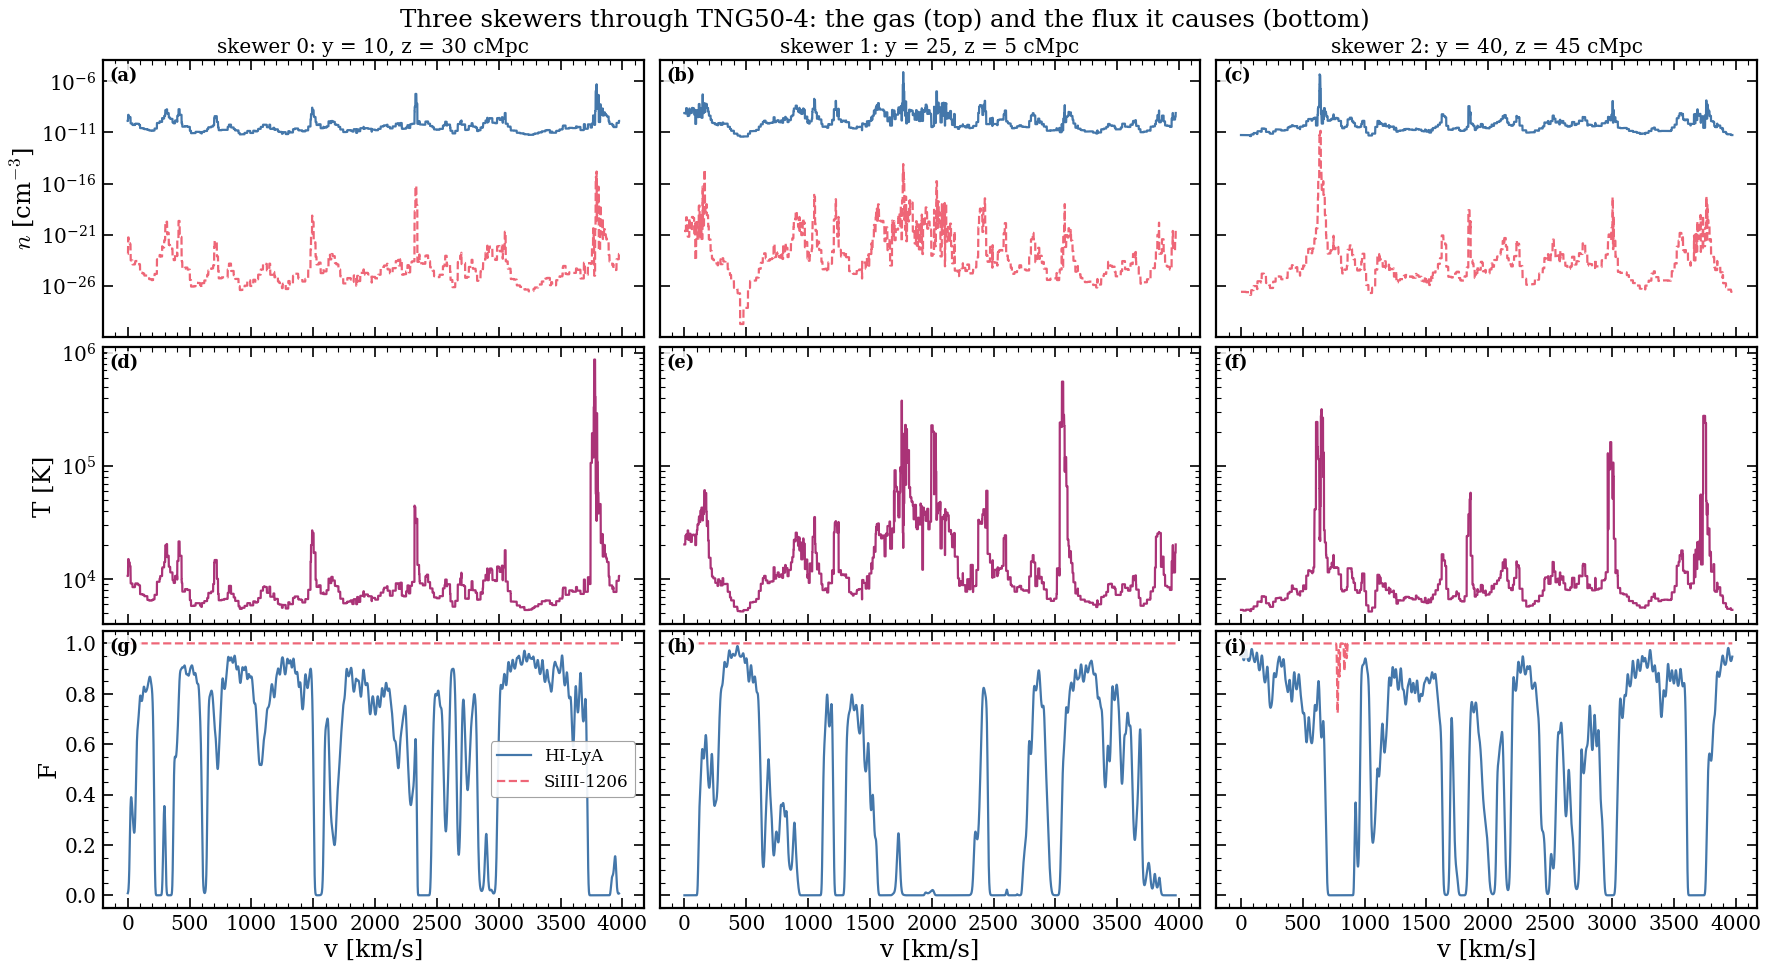

<F>: Lya 0.506, Si III 0.9996


In [5]:
lines = LineBundle(["HI-LyA", "SiIII-1206"], ref_line_id="HI-LyA")
velocities, tau = sk.optical_depth(lines)
flux = np.exp(-tau)
fields = sk.fields(lines.species_keys)
sampled = fields.sample(bundle.quadri_vectors[0], bundle.los_directions)
a_pts = np.asarray(bundle.quadri_vectors[0][..., 0])
v_pts = phys.c_kms * np.log(a_pts[:, :1] / a_pts)
fig, axs = plt.subplots(3, 3, figsize=(22, 12), sharex=True, sharey="row", layout="constrained")
for k in range(3):
    for j, l in enumerate(lines.lines):
        sty = MS["default"] if j == 0 else MS["matched"]
        axs[0, k].semilogy(v_pts[k], np.asarray(sampled[l.species]["number_density"])[k] / H.a ** 3, color=EC[l.species], **sty)
        axs[2, k].plot(velocities, flux[j, k], color=EC[l.species], **sty, label=l.id)
    axs[1, k].semilogy(v_pts[k], np.asarray(sampled["HI"]["temperature"])[k], color=EC["temperature"])
    axs[0, k].set_title(f"skewer {k}: y = {points[k, 0, 1]:.0f}, z = {points[k, 0, 2]:.0f} cMpc", fontsize=18); axs[2, k].set_xlabel("v [km/s]")
axs[0, 0].set_ylabel(r"$n$ [cm$^{-3}$]"); axs[1, 0].set_ylabel("T [K]"); axs[2, 0].set_ylabel("F"); axs[2, 0].legend()
add_panel_letters(axs, size=16); fig.suptitle("Three skewers through TNG50-4: the gas (top) and the flux it causes (bottom)", fontsize=22); plt.show()
print(f"<F>: Lya {flux[0].mean():.3f}, Si III {flux[1].mean():.4f}")

## 4 · Precision, zoom-in and devices

The τ of the three skewers again, with the opt-in float32 kernel (`IntegrationOptions(dtype="float32")`). The
float64 default is the reference. The inset zooms into one absorber. The same calls take `devices=jax.devices()`
to shard the work over several devices (notebook 08 and `docs/usage.md`).

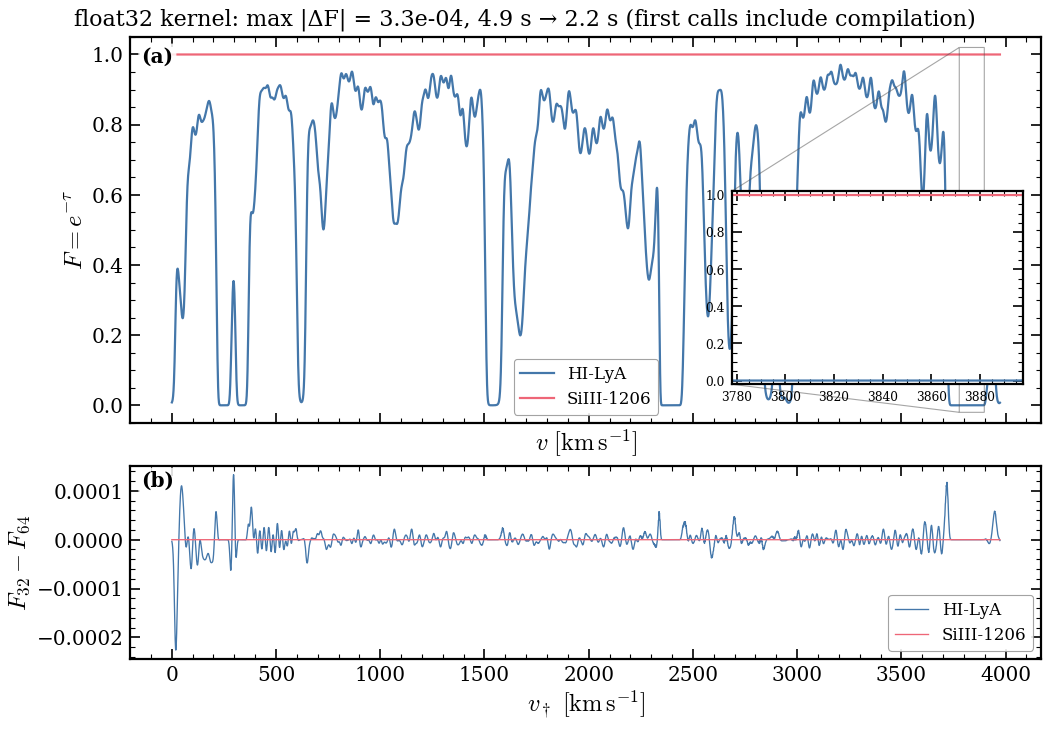

In [6]:
import time
t0 = time.perf_counter(); _, tau64 = sk.optical_depth(lines); t64 = time.perf_counter() - t0
t0 = time.perf_counter(); _, tau32 = sk.optical_depth(lines, integ=IntegrationOptions(dtype="float32")); t32 = time.perf_counter() - t0
fig, axs = plt.subplots(2, 1, figsize=FIGSIZES["tall"], sharex=True, gridspec_kw={"height_ratios": [2, 1]}, layout="constrained")
plot_spectra(axs[0], velocities, np.exp(-tau64[:, 0]), [l.id for l in lines.lines], total=False)
for j, l in enumerate(lines.lines):
    axs[1].plot(velocities, np.exp(-tau32[j, 0]) - np.exp(-tau64[j, 0]), color=EC[l.id], lw=1.2, label=l.id)
k0 = int(np.argmin(np.exp(-tau64[0, 0])))
zoom_inset(axs[0], (velocities[k0] - 60, velocities[k0] + 60), (-0.02, 1.02), bounds=(0.66, 0.1, 0.32, 0.5))
axs[1].set(xlabel=LABELS["v_dagger"], ylabel=r"$F_{32} - F_{64}$"); axs[0].legend(); axs[1].legend()
add_panel_letters(axs); fig.suptitle(f"float32 kernel: max |ΔF| = {np.abs(np.exp(-tau32) - np.exp(-tau64)).max():.1e}, "
                                     f"{t64:.1f} s → {t32:.1f} s (first calls include compilation)", fontsize=20); plt.show()

**Options.** `ExtractionOptions`: `deposition` ("voronoi" | "tophat" | "points"), `mass_unit` ("amu" | "proton"),
`T_constants`, `b_constants` ("codata" | "fake_spectra"), `x_HI_model` ("stored_sf" | "stored" | "fake_sf" |
"rahmati_all"), `cloudy_density` ("hydrogen" | "fake_spectra"), `cloudy_interpolation` ("linear" | "cubic").
`IntegrationOptions`: `frame` ("exact" | "snapshot"), `normalisation`, `detuning` ("exact" | "linear"),
`periodic`. The non-default values reproduce fake_spectra (notebook 06). Checks:
`scripts/validation/check_tng_fields.py`, `check_tng_optical_depth.py`.

## Summary

- Six layers go from the HDF5 snapshot to τ: reader, cells, physics, selection, deposition, absorbers.
  `SimulationSkewers` runs them for any options.
- The Voronoi deposition conserves the column for any sampling. The flux follows the gas structures along each
  skewer.
- The opt-in float32 kernel changes F by ~1e-3 at most (here 2-3x faster on the CPU). It is a speed option for large
  runs; the float64 default is the reference.
- Checks: `scripts/validation/check_tng_fields.py`, `check_tng_optical_depth.py`.